# Ejemplo 2. Diagrama de Bode de un sistema de primer orden

**Instrumentación y Control — Respuesta en frecuencia**

Considere la planta

$$
\boxed{G(s)=\frac{1}{s+1}}
$$

El objetivo es **calcular y representar su respuesta en frecuencia**, e interpretar qué ocurre con las señales sinusoidales a medida que aumenta la frecuencia.

Al sustituir $s=j\omega$:

$$
G(j\omega)=\frac{1}{1+j\omega},\qquad
|G(j\omega)|=\frac{1}{\sqrt{1+\omega^2}},\qquad
\phi(\omega)=-\tan^{-1}(\omega).
$$

La magnitud expresada en decibelios es

$$
\boxed{M(\omega)=-10\log_{10}(1+\omega^2)}.
$$

En el diagrama de Bode, la **frecuencia angular** se expresa en $\mathrm{rad/s}$, la **magnitud** en $\mathrm{dB}$ y la **fase** en grados. Se consideran variables de entrada y salida adimensionales.

## 1. Calcular la magnitud y la fase

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Intervalo de frecuencias: de 0.1 a 1000 rad/s, en escala logarítmica.
omega = np.logspace(-1, 3, 500)

# Respuesta en frecuencia calculada directamente de G(jω).
Gjw = 1 / (1 + 1j * omega)

# Magnitud lineal, magnitud en decibelios y fase en grados.
magnitud = np.abs(Gjw)
magnitud_db = 20 * np.log10(magnitud)
fase_grados = np.angle(Gjw, deg=True)

# Verificación con las expresiones analíticas de la lectura.
assert np.allclose(magnitud, 1 / np.sqrt(1 + omega**2))
assert np.allclose(magnitud_db, -10 * np.log10(1 + omega**2))
assert np.allclose(fase_grados, -np.degrees(np.arctan(omega)))

print('Se verificaron las fórmulas analíticas de magnitud y fase.')

Se verificaron las fórmulas analíticas de magnitud y fase.


## 2. Construir el diagrama de Bode

El diagrama de Bode muestra la **magnitud en dB** y la **fase en grados** con un eje horizontal logarítmico. La frecuencia de quiebre de esta planta se encuentra en $\omega_p=1\;\mathrm{rad/s}$.

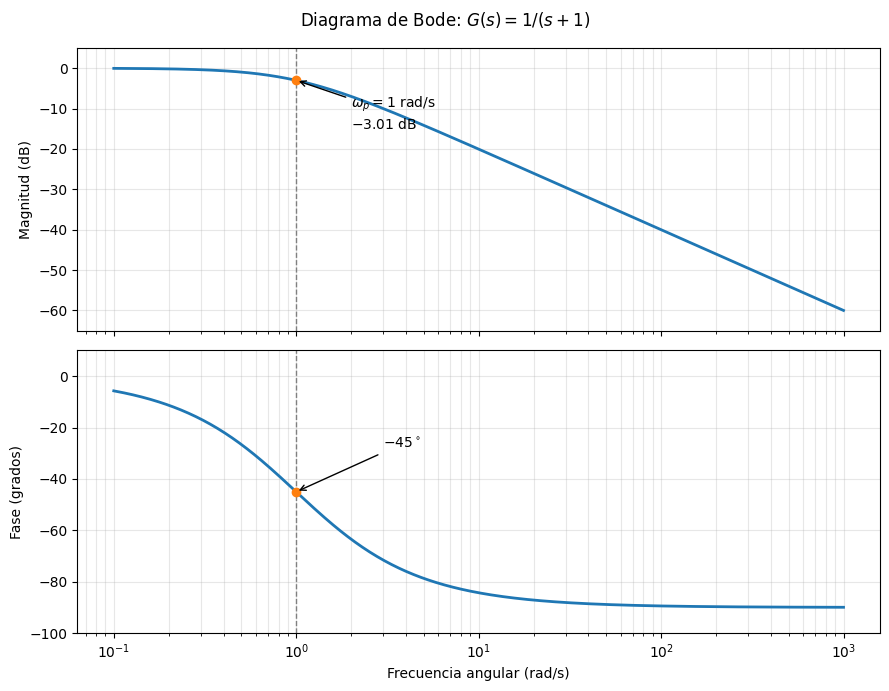

In [2]:
# Frecuencia de quiebre y valores exactos en ese punto.
omega_p = 1.0
M_p = -10 * np.log10(1 + omega_p**2)
phi_p = -np.degrees(np.arctan(omega_p))

fig, (ax_mag, ax_fase) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

# Magnitud.
ax_mag.semilogx(omega, magnitud_db, linewidth=2, label='Magnitud')
ax_mag.plot(omega_p, M_p, 'o', zorder=3)
ax_mag.axvline(omega_p, linestyle='--', linewidth=1, color='gray')
ax_mag.annotate(r'$\omega_p=1$ rad/s' + '\n' + r'$-3.01$ dB',
                xy=(omega_p, M_p), xytext=(2.0, -15),
                arrowprops=dict(arrowstyle='->'), fontsize=10)
ax_mag.set(ylabel='Magnitud (dB)', ylim=(-65, 5))
ax_mag.grid(True, which='both', alpha=0.3)

# Fase.
ax_fase.semilogx(omega, fase_grados, linewidth=2, label='Fase')
ax_fase.plot(omega_p, phi_p, 'o', zorder=3)
ax_fase.axvline(omega_p, linestyle='--', linewidth=1, color='gray')
ax_fase.annotate(r'$-45^\circ$', xy=(omega_p, phi_p),
                 xytext=(3.0, -28), arrowprops=dict(arrowstyle='->'), fontsize=10)
ax_fase.set(xlabel='Frecuencia angular (rad/s)',
            ylabel='Fase (grados)', ylim=(-100, 10))
ax_fase.grid(True, which='both', alpha=0.3)

fig.suptitle(r'Diagrama de Bode: $G(s)=1/(s+1)$')
fig.tight_layout()
fig.savefig('Ejemplo_2_Bode_Primer_Orden.png', dpi=180, bbox_inches='tight')
plt.show()

### Interpretación

- **Frecuencias bajas ($\omega\ll1$):** la magnitud se aproxima a $0\;\mathrm{dB}$, equivalente a una relación de amplitudes cercana a $1$, y la fase se aproxima a $0^\circ$.
- **Frecuencia de quiebre ($\omega=1\;\mathrm{rad/s}$):** la magnitud vale aproximadamente $-3.01\;\mathrm{dB}$ y la fase es $-45^\circ$.
- **Frecuencias altas ($\omega\gg1$):** la magnitud disminuye aproximadamente $20\;\mathrm{dB}$ por década y la fase se aproxima a $-90^\circ$.

Una *década* es un incremento de la frecuencia por un factor de diez, por ejemplo de $1$ a $10\;\mathrm{rad/s}$.

## 3. Evaluar frecuencias representativas

In [3]:
frecuencias = np.array([0.1, 1, 10, 100, 1000], dtype=float)
respuesta = 1 / (1 + 1j * frecuencias)

print(f'{"ω (rad/s)":>11} | {"|G(jω)|":>10} | {"M (dB)":>10} | {"Fase (°)":>10}')
print('-' * 54)
for w, g in zip(frecuencias, respuesta):
    print(f'{w:11.1f} | {abs(g):10.4f} | {20*np.log10(abs(g)):10.2f} | {np.angle(g,deg=True):10.2f}')

  ω (rad/s) |    |G(jω)| |     M (dB) |   Fase (°)
------------------------------------------------------
        0.1 |     0.9950 |      -0.04 |      -5.71
        1.0 |     0.7071 |      -3.01 |     -45.00
       10.0 |     0.0995 |     -20.04 |     -84.29
      100.0 |     0.0100 |     -40.00 |     -89.43
     1000.0 |     0.0010 |     -60.00 |     -89.94


## 4. Relacionar el Bode con las señales en el tiempo

Para una entrada $x(t)=\sin(\omega t)$, la respuesta permanente es

$$
\boxed{y_{\mathrm{per}}(t)=|G(j\omega)|\sin\!\left(\omega t+\phi(\omega)\right)}.
$$

El siguiente gráfico usa el eje horizontal $\omega t$ (fase de la señal, en radianes) para visualizar **tres frecuencias sobre un mismo intervalo de cuatro períodos**. Esto permite comparar amplitud y atraso de fase; no representa un mismo intervalo de tiempo físico para las tres frecuencias.

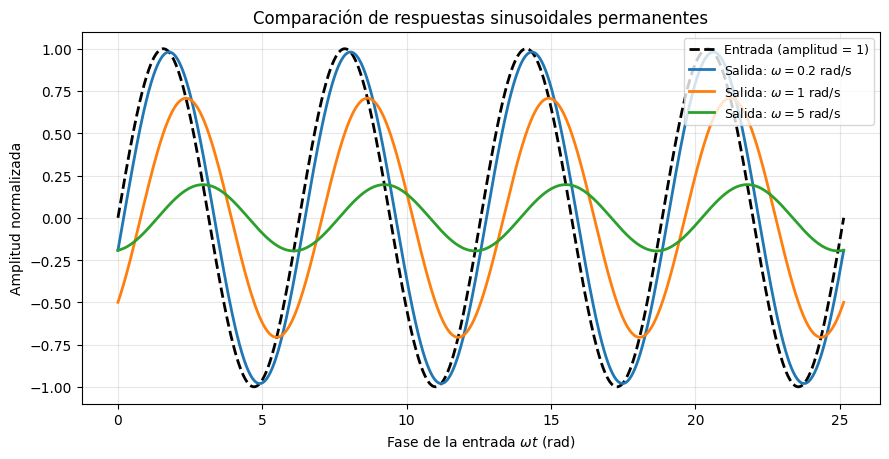

In [4]:
frecuencias_comparacion = [0.2, 1.0, 5.0]
fase_temporal = np.linspace(0, 8*np.pi, 1200)
entrada = np.sin(fase_temporal)

fig, ax = plt.subplots(figsize=(9, 4.7))
ax.plot(fase_temporal, entrada, color='black', linewidth=2,
        linestyle='--', label='Entrada (amplitud = 1)')

for w in frecuencias_comparacion:
    g = 1 / (1 + 1j*w)
    salida = np.abs(g) * np.sin(fase_temporal + np.angle(g))
    ax.plot(fase_temporal, salida, linewidth=2,
            label=fr'Salida: $\omega={w:g}$ rad/s')

ax.set(xlabel=r'Fase de la entrada $\omega t$ (rad)',
       ylabel='Amplitud normalizada',
       title='Comparación de respuestas sinusoidales permanentes')
ax.grid(alpha=0.3)
ax.legend(loc='upper right', fontsize=9)
fig.tight_layout()
fig.savefig('Ejemplo_2_Comparacion_Sinusoidal.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Exploración opcional: cambiar la frecuencia

Ejecute la celda y cambie $\omega$ para observar cómo cambia la salida. El eje horizontal ahora sí representa el **tiempo real**, en segundos, para cada frecuencia seleccionada.

In [5]:
# Celda opcional para Google Colab y Jupyter con ipywidgets disponible.
try:
    import ipywidgets as widgets
    from IPython.display import display

    selector = widgets.SelectionSlider(
        options=[('0.1 rad/s', 0.1), ('0.2 rad/s', 0.2),
                 ('0.5 rad/s', 0.5), ('1 rad/s', 1.0),
                 ('2 rad/s', 2.0), ('5 rad/s', 5.0), ('10 rad/s', 10.0)],
        value=1.0, description='Frecuencia:', continuous_update=False
    )

    def mostrar_respuesta(omega_elegida):
        G = 1/(1 + 1j*omega_elegida)
        t = np.linspace(0, 3*2*np.pi/omega_elegida, 700)
        x = np.sin(omega_elegida*t)
        y = np.abs(G)*np.sin(omega_elegida*t + np.angle(G))

        fig, ax = plt.subplots(figsize=(9, 3.7))
        ax.plot(t, x, '--', color='black', linewidth=1.9, label='Entrada')
        ax.plot(t, y, linewidth=2, label='Salida permanente')
        ax.set(xlabel='Tiempo (s)', ylabel='Amplitud normalizada', ylim=(-1.15, 1.15),
               title=(fr'$\omega={omega_elegida:g}$ rad/s; '
                      fr'$|G|={abs(G):.3f}$; '
                      fr'$\phi={np.angle(G,deg=True):.1f}^\circ$'))
        ax.grid(alpha=0.3)
        ax.legend()
        plt.show()

    panel = widgets.interactive(mostrar_respuesta, omega_elegida=selector)
    display(panel)
except ImportError:
    print('La exploración interactiva requiere ipywidgets. Las gráficas anteriores funcionan sin él.')

La exploración interactiva requiere ipywidgets. Las gráficas anteriores funcionan sin él.


## Actividad de interpretación

1. Compare la magnitud en $\omega=0.1$, $1$ y $10\;\mathrm{rad/s}$. ¿En qué caso la amplitud de salida es más cercana a la de entrada?
2. ¿Qué significa que la magnitud sea $-3.01\;\mathrm{dB}$ cuando $\omega=1\;\mathrm{rad/s}$? Exprese también la relación en amplitud lineal.
3. Compare la magnitud en $\omega=10$ y $100\;\mathrm{rad/s}$. ¿Cuántos decibelios aproximadamente disminuyó al aumentar una década?
4. Describa cómo cambia el atraso de fase a medida que aumenta $\omega$.

**Conclusión.** El polo $s=-1$ hace que la planta atenúe progresivamente las señales sinusoidales de alta frecuencia e introduzca un atraso de fase que se aproxima a $90^\circ$.